# Loading TESS Light Curves

In this notebook, we load and visualize TESS light curve data for multiple
targets using the `lightkurve` library.

The goal is to build a reusable data-loading function that works for any
TESS Input Catalog (TIC) ID.



In [1]:
%matplotlib inline


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk




C:\Users\SURA\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
def load_tess_lightcurve(tic_id):
    """
    Load and stitch all SPOC TESS light curves for a given TIC ID.
    """
    search_result = lk.search_lightcurve(
        f"TIC {tic_id}",
        mission="TESS",
        author="SPOC"
    )
    
    if len(search_result) == 0:
        raise ValueError("No SPOC light curve found for this TIC ID.")
    
    lc_collection = search_result.download_all()
    lc = lc_collection.stitch()
    
    return lc


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

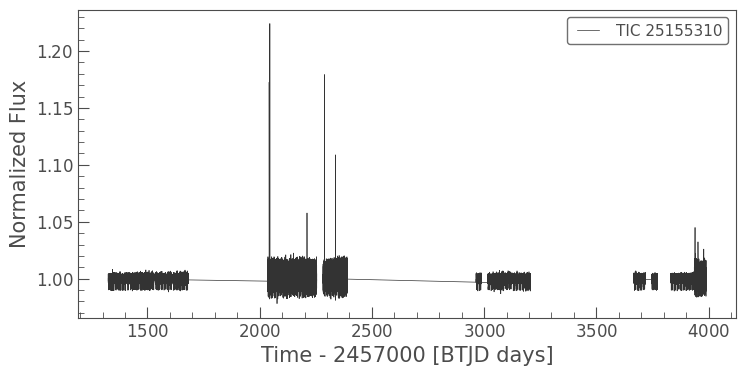

In [4]:
tic_id = 25155310
lc = load_tess_lightcurve(tic_id)
lc.plot()

